Bisection equilibrium temperature: 27.525211 C
Fixed-point equilibrium temperature: 27.525211 C
Fixed-point iterations: 14


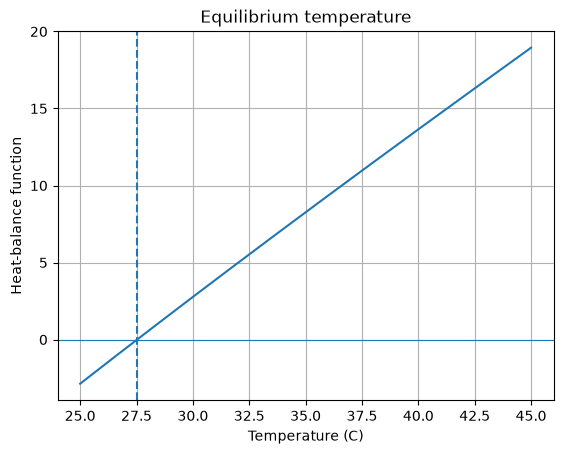

In [2]:
import numpy as np
from scipy.optimize import root_scalar
import matplotlib.pyplot as plt

#I. Root Finding: Bisection and Fixed-Point Methods

# Heat-balance model:
# f(T) = 0 means heat gain equals heat loss.
def heat_balance(T):
    return T - 25 - 10*np.exp(-T/20)

# Bisection: bracket a sign change
solution = root_scalar(
    heat_balance,
    bracket=[25, 45],
    method="bisect",
    xtol=1e-10
)

# Fixed-point form:
# T = 25 + 10*exp(-T/20)
def g(T):
    return 25 + 10*np.exp(-T/20)

T = 35.0
history = [T]

for _ in range(100):
    T_new = g(T)
    history.append(T_new)

    if abs(T_new - T) < 1e-10:
        break

    T = T_new

print(f"Bisection equilibrium temperature: {solution.root:.6f} C")
print(f"Fixed-point equilibrium temperature: {history[-1]:.6f} C")
print("Fixed-point iterations:", len(history) - 1)

temps = np.linspace(25, 45, 300)
plt.plot(temps, heat_balance(temps))
plt.axhline(0, linewidth=0.8)
plt.axvline(solution.root, linestyle="--")
plt.xlabel("Temperature (C)")
plt.ylabel("Heat-balance function")
plt.title("Equilibrium temperature")
plt.grid(True)
plt.show()